In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pycaret.classification import setup, compare_models, plot_model

In [2]:
df = pd.read_csv("data/mnist_train.csv")
len(df)

59999

In [3]:
df.head()

,5,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.608,0.609,0.610,0.611,0.612,0.613,0.614,0.615,0.616,0.617
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
y = df.iloc[:,0]
x = df.iloc[:, 1:]

x_train, x_test, y_train, y_test = x[:50000], x[50000:], y[:50000], y[50000:]

In [5]:
x_train.shape

(50000, 784)

(-0.5, 27.5, 27.5, -0.5)

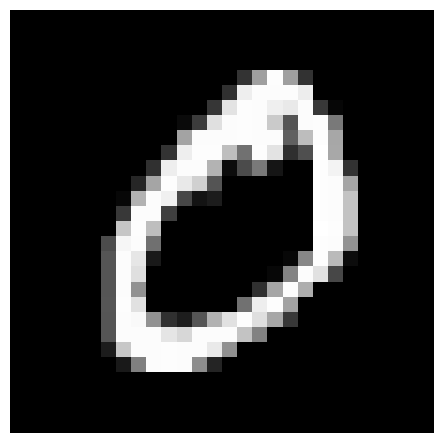

In [8]:
plt.imshow(np.array(x.iloc[0]).reshape(28,28), cmap='gray')
plt.axis('off')

In [9]:
sample = pd.DataFrame(x_train).add_prefix("px").sample(5000, random_state=42)

In [10]:
sample["is_5"] = y_train[sample.index] == 5

In [11]:
sample.head()

,px0,px0.1,px0.2,px0.3,px0.4,px0.5,px0.6,px0.7,px0.8,px0.9,...,px0.609,px0.610,px0.611,px0.612,px0.613,px0.614,px0.615,px0.616,px0.617,is_5
33553,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,False
9427,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,False
199,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,False
12447,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,False
39489,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,False


In [12]:
setup(sample, target="is_5", session_id=42)

,Description,Value
0,Session id,42
1,Target,is_5
2,Target type,Binary
3,Original data shape,"(5000, 785)"
4,Transformed data shape,"(5000, 785)"
5,Transformed train set shape,"(3500, 785)"
6,Transformed test set shape,"(1500, 785)"
7,Numeric features,784
8,Preprocess,True
9,Imputation type,simple


In [13]:
best = compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
knn,K Neighbors Classifier,0.9843,0.9907,0.8947,0.9383,0.9152,0.9065,0.9073,1.2080
et,Extra Trees Classifier,0.9769,0.9955,0.7623,0.9933,0.8608,0.8485,0.8583,0.3870
gbc,Gradient Boosting Classifier,0.9743,0.9855,0.7626,0.9605,0.8490,0.8352,0.8425,3.3900
rf,Random Forest Classifier,0.9691,0.9946,0.6815,0.9923,0.8061,0.7901,0.8076,0.5230
ada,Ada Boost Classifier,0.9606,0.9598,0.7174,0.8490,0.7748,0.7535,0.7582,1.0130
dt,Decision Tree Classifier,0.9500,0.8647,0.7594,0.7290,0.7425,0.7149,0.7159,0.3220
svm,SVM - Linear Kernel,0.9460,0.9527,0.6577,0.7518,0.6969,0.6676,0.6720,0.3230
lr,Logistic Regression,0.9431,0.9471,0.7270,0.6946,0.7084,0.6769,0.6784,4.0120
ridge,Ridge Classifier,0.9343,0.9271,0.4628,0.7620,0.5710,0.5380,0.5601,0.3460
lda,Linear Discriminant Analysis,0.9323,0.9268,0.6004,0.6658,0.6291,0.5921,0.5944,0.9330


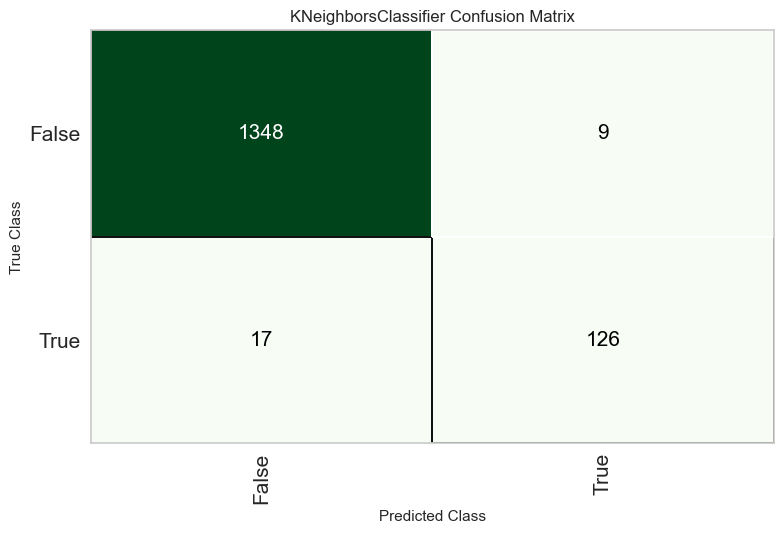

In [14]:
plot_model(best, plot="confusion_matrix")

In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
model = KNeighborsClassifier(n_jobs=1)
model.fit(x_train, y_train == 5)
y_pred = model.predict(np.array(x_test.iloc[0]).reshape(1,-1))
y_pred

array([False])

In [18]:
print(classification_report(y_test == 5, y_pred, digits=4))

              precision    recall  f1-score   support

       False     0.9943    0.9976    0.9959      9084
        True     0.9751    0.9432    0.9589       915

    accuracy                         0.9926      9999
   macro avg     0.9847    0.9704    0.9774      9999
weighted avg     0.9925    0.9926    0.9925      9999



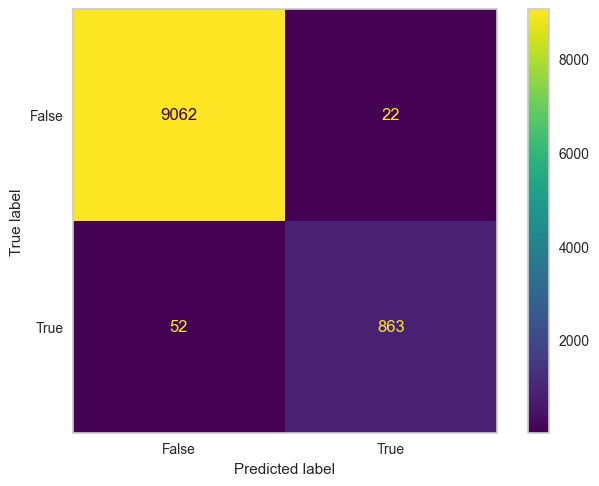

In [22]:
display = ConfusionMatrixDisplay.from_predictions(y_test == 5, y_pred)
display.ax_.grid(False)

In [26]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_predict

In [30]:
y_pred_SGD = cross_val_predict(SGDClassifier(random_state=42), x_train, y_train == 5, cv=3)

In [32]:
print(classification_report(y_train == 5, y_pred_SGD, digits=4))

              precision    recall  f1-score   support

       False     0.9740    0.9800    0.9770     45495
        True     0.7849    0.7356    0.7595      4505

    accuracy                         0.9580     50000
   macro avg     0.8795    0.8578    0.8682     50000
weighted avg     0.9569    0.9580    0.9574     50000

